In [1]:
!pip uninstall -y dopamine-rl
!pip install -q ultralytics roboflow gradio pyyaml

Found existing installation: dopamine_rl 4.1.2
Uninstalling dopamine_rl-4.1.2:
  Successfully uninstalled dopamine_rl-4.1.2


In [2]:
# Import libraries and set random seed
import os
import gc
import json
import time
import random
import shutil
import math
from pathlib import Path
from datetime import datetime

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO
from roboflow import Roboflow

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Training will be very slow.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
# Connect to Roboflow and download the dataset
ROBOFLOW_API_KEY = "GyXsDB8A41Cshaf1RNOr"

rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = (
    rf.workspace("university-federico-ii-ygjoa")
      .project("road-damage-detection-i40w8")
)

version = project.version(3)

dataset = version.download(
    "yolov8",
    location="/kaggle/working/dataset",
    overwrite=True
)

print("Downloaded dataset:", dataset.location)
print(project)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset in yolov8:: 100%|██████████| 2836/2836 [00:00<00:00, 6077.08it/s]

Downloaded dataset: /kaggle/working/dataset
{
  "name": "Road damage detection",
  "type": "object-detection",
  "workspace": "university-federico-ii-ygjoa"
}


In [4]:
# Locate and read the dataset configuration
DATASET_ROOT = Path("/kaggle/working/dataset").resolve()
ORIGINAL_YAML = DATASET_ROOT / "data.yaml"

if not ORIGINAL_YAML.exists():
    candidates = list(DATASET_ROOT.rglob("data.yaml"))
    if not candidates:
        raise FileNotFoundError("Could not find data.yaml after Roboflow download.")
    ORIGINAL_YAML = candidates[0]

with open(ORIGINAL_YAML, "r", encoding="utf-8") as f:
    raw_data_cfg = yaml.safe_load(f)

print("Original data.yaml:")
print(raw_data_cfg)

Original data.yaml:
{'names': ['alligator cracking', 'edge cracking', 'longitudinal cracking', 'manhole', 'patching', 'pothole', 'rutting', 'transverse cracking'], 'nc': 8, 'roboflow': {'license': 'CC BY 4.0', 'project': 'road-damage-detection-i40w8', 'url': 'https://universe.roboflow.com/university-federico-ii-ygjoa/road-damage-detection-i40w8/dataset/3', 'version': 3, 'workspace': 'university-federico-ii-ygjoa'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [5]:
# Fix dataset paths for Kaggle
def first_existing_dir(candidates):
    for p in candidates:
        p = Path(p)
        if p.exists() and p.is_dir():
            return p.resolve()
    return None

train_images = first_existing_dir([
    DATASET_ROOT / "train" / "images",
    DATASET_ROOT.parent / "train" / "images",
])

val_images = first_existing_dir([
    DATASET_ROOT / "valid" / "images",
    DATASET_ROOT / "val" / "images",
    DATASET_ROOT.parent / "valid" / "images",
    DATASET_ROOT.parent / "val" / "images",
])

test_images = first_existing_dir([
    DATASET_ROOT / "test" / "images",
    DATASET_ROOT.parent / "test" / "images",
])

if train_images is None:
    raise FileNotFoundError("train/images not found.")
if val_images is None:
    raise FileNotFoundError("valid/images or val/images not found.")
if test_images is None:
    raise FileNotFoundError(
        "test/images not found. A held-out test set is required for the final unbiased comparison."
    )

CLASS_NAMES = raw_data_cfg.get("names", [])
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES, key=lambda x: int(x))]
NUM_CLASSES = len(CLASS_NAMES)

CLEAN_YAML = DATASET_ROOT / "data_kaggle.yaml"
clean_cfg = {
    "train": str(train_images),
    "val": str(val_images),
    "test": str(test_images),
    "nc": NUM_CLASSES,
    "names": CLASS_NAMES,
}

with open(CLEAN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(clean_cfg, f, sort_keys=False, allow_unicode=True)

DATA_YAML = str(CLEAN_YAML)

print("Clean YAML:", DATA_YAML)
print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)
print("Train:", train_images)
print("Validation:", val_images)
print("Test:", test_images)

Clean YAML: /kaggle/working/dataset/data_kaggle.yaml
Number of classes: 8
Classes: ['alligator cracking', 'edge cracking', 'longitudinal cracking', 'manhole', 'patching', 'pothole', 'rutting', 'transverse cracking']
Train: /kaggle/working/dataset/train/images
Validation: /kaggle/working/dataset/valid/images
Test: /kaggle/working/dataset/test/images


In [6]:
# Count images and inspect dataset splits
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_files(folder):
    folder = Path(folder)
    return sorted([p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXTS])

def labels_dir_from_images(images_dir):
    return Path(images_dir).parent / "labels"

def split_stats(images_dir):
    imgs = image_files(images_dir)
    labels_dir = labels_dir_from_images(images_dir)
    labels = list(labels_dir.glob("*.txt")) if labels_dir.exists() else []
    return len(imgs), len(labels)

stats = []
for split_name, folder in [
    ("Train", train_images),
    ("Validation", val_images),
    ("Test", test_images),
]:
    n_img, n_lab = split_stats(folder)
    stats.append({"Split": split_name, "Images": n_img, "Label files": n_lab})

split_df = pd.DataFrame(stats)
display(split_df)

,Split,Images,Label files
0,Train,1269,1269
1,Validation,109,109
2,Test,34,34


In [7]:
# Count objects for each class
def class_distribution(images_dir):
    labels_dir = labels_dir_from_images(images_dir)
    counts = np.zeros(NUM_CLASSES, dtype=int)

    for label_file in labels_dir.glob("*.txt"):
        with open(label_file, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls_id = int(float(parts[0]))
                    if 0 <= cls_id < NUM_CLASSES:
                        counts[cls_id] += 1
    return counts

dist_rows = []
for split_name, folder in [
    ("Train", train_images),
    ("Validation", val_images),
    ("Test", test_images),
]:
    counts = class_distribution(folder)
    for class_id, count in enumerate(counts):
        dist_rows.append({
            "Split": split_name,
            "Class ID": class_id,
            "Class": CLASS_NAMES[class_id],
            "Objects": int(count),
        })

class_dist_df = pd.DataFrame(dist_rows)
display(class_dist_df)

,Split,Class ID,Class,Objects
0,Train,0,alligator cracking,663
1,Train,1,edge cracking,263
2,Train,2,longitudinal cracking,1043
3,Train,3,manhole,165
4,Train,4,patching,117
5,Train,5,pothole,192
6,Train,6,rutting,36
7,Train,7,transverse cracking,768
8,Validation,0,alligator cracking,39
9,Validation,1,edge cracking,25


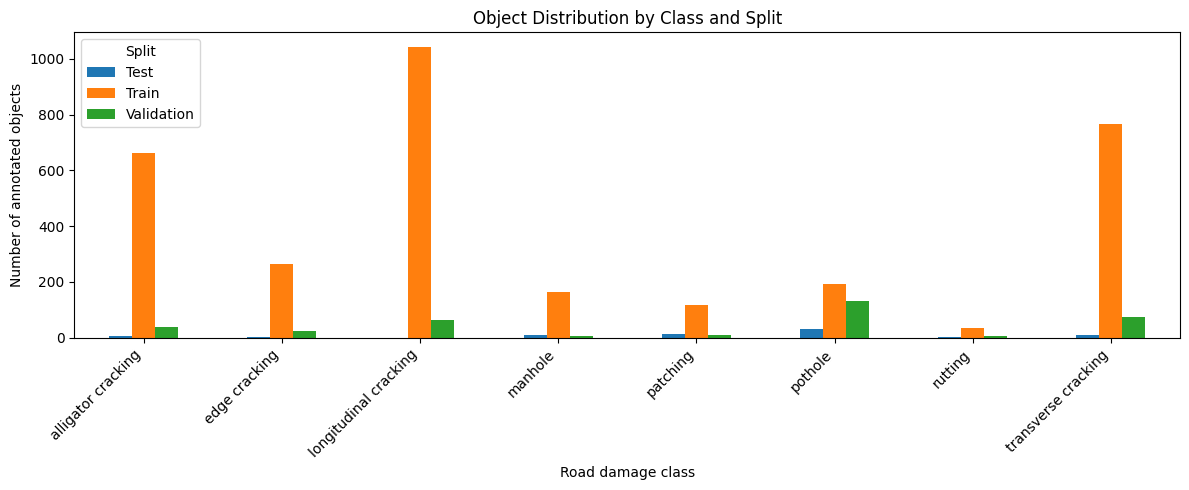

In [8]:
# Plot class distribution
pivot = class_dist_df.pivot(index="Class", columns="Split", values="Objects").fillna(0)
ax = pivot.plot(kind="bar", figsize=(12, 5))
ax.set_title("Object Distribution by Class and Split")
ax.set_ylabel("Number of annotated objects")
ax.set_xlabel("Road damage class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

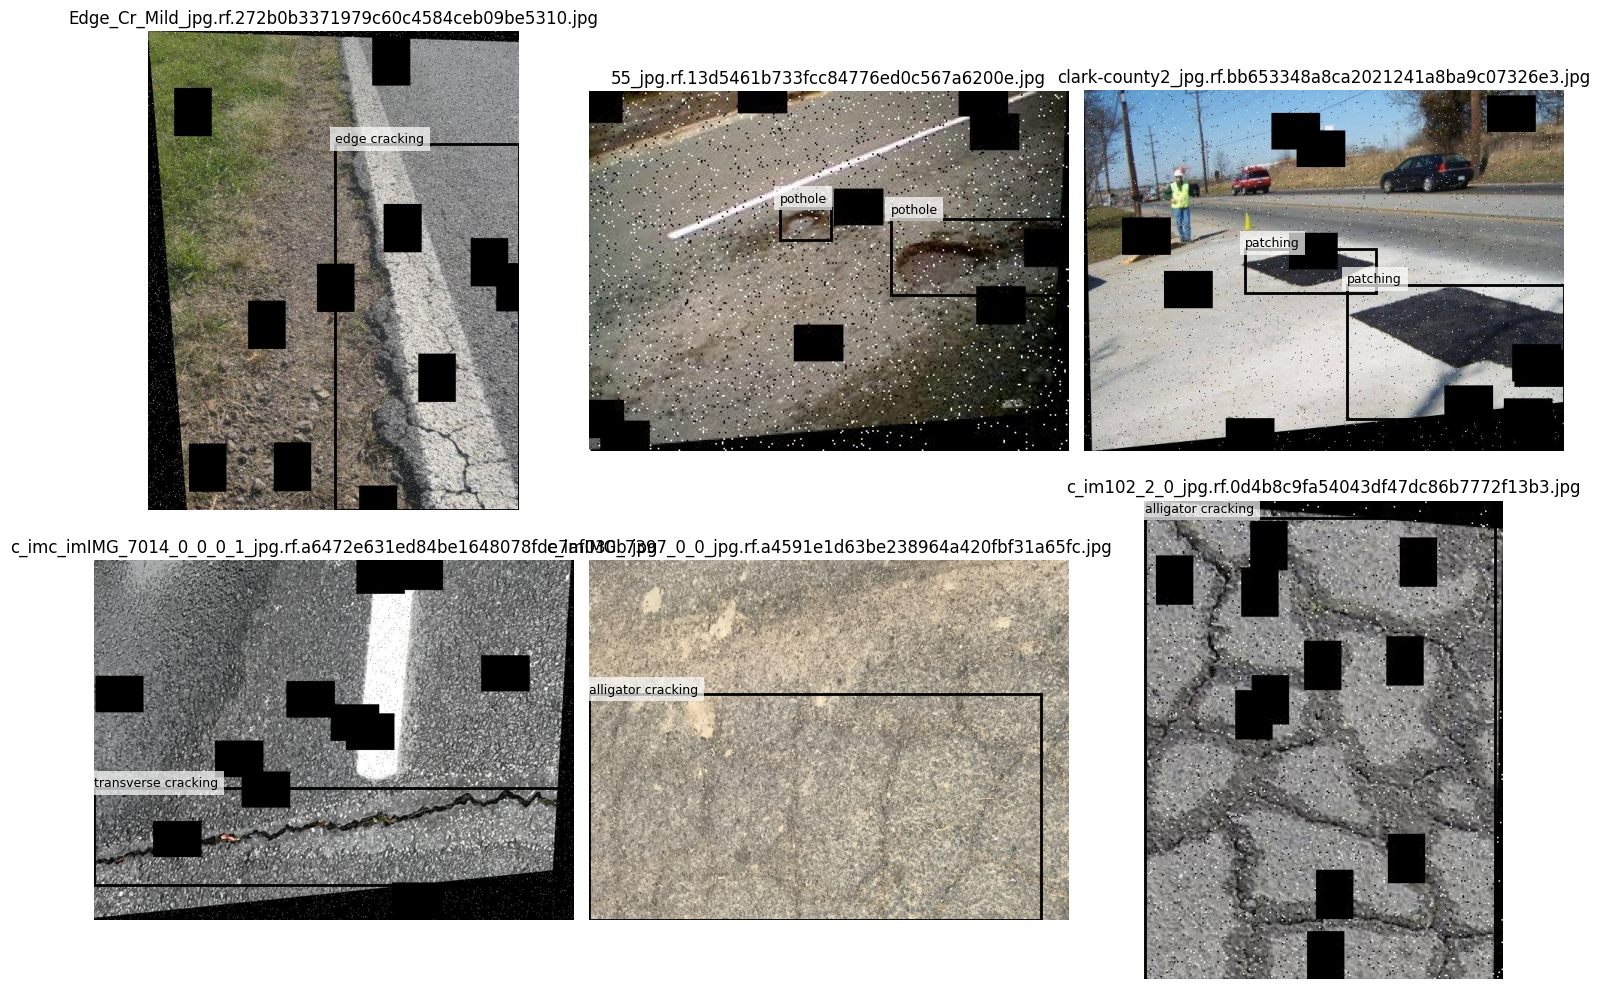

In [9]:
# Visualize sample images with bounding boxes
def load_yolo_labels(label_path, img_w, img_h):
    items = []
    if not Path(label_path).exists():
        return items

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue

            cls_id = int(float(parts[0]))
            xc, yc, w, h = map(float, parts[1:5])

            x1 = (xc - w / 2) * img_w
            y1 = (yc - h / 2) * img_h
            x2 = (xc + w / 2) * img_w
            y2 = (yc + h / 2) * img_h

            items.append((cls_id, x1, y1, x2, y2))
    return items

def show_dataset_samples(images_dir, n=6):
    imgs = image_files(images_dir)
    if not imgs:
        print("No images found.")
        return

    sample = random.sample(imgs, min(n, len(imgs)))
    cols = 3
    rows = math.ceil(len(sample) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, img_path in zip(axes, sample):
        image = Image.open(img_path).convert("RGB")
        w, h = image.size
        labels_path = Path(images_dir).parent / "labels" / f"{img_path.stem}.txt"
        anns = load_yolo_labels(labels_path, w, h)

        ax.imshow(image)
        ax.set_title(img_path.name)
        ax.axis("off")

        for cls_id, x1, y1, x2, y2 in anns:
            rect = plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, linewidth=2
            )
            ax.add_patch(rect)
            ax.text(
                x1, max(0, y1 - 4),
                CLASS_NAMES[cls_id],
                fontsize=9,
                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
            )

    plt.tight_layout()
    plt.show()

show_dataset_samples(train_images, n=6)

In [10]:
# Define experiment settings and YOLO models
WORK_DIR = Path("/kaggle/working/road_damage_project")
RUNS_DIR = WORK_DIR / "runs"
RESULTS_DIR = WORK_DIR / "results"
EXPORT_DIR = WORK_DIR / "deployment"

for d in [WORK_DIR, RUNS_DIR, RESULTS_DIR, EXPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

MODELS = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt",
}

QUICK_MODE = False

if QUICK_MODE:
    BASELINE_EPOCHS = 3
    TUNE_EPOCHS = 3
    BATCH = 8
    TUNE_CONFIGS = [
        {"name": "quick_adamw", "optimizer": "AdamW", "lr0": 0.001, "weight_decay": 0.0005, "mosaic": 0.5},
    ]
else:
    BASELINE_EPOCHS = 30
    TUNE_EPOCHS = 20
    BATCH = 16
    TUNE_CONFIGS = [
        {
            "name": "adamw_lr1e3",
            "optimizer": "AdamW",
            "lr0": 0.001,
            "weight_decay": 0.0005,
            "mosaic": 1.0,
        },
        {
            "name": "adamw_lr5e4",
            "optimizer": "AdamW",
            "lr0": 0.0005,
            "weight_decay": 0.001,
            "mosaic": 0.5,
        },
        {
            "name": "sgd_lr1e2",
            "optimizer": "SGD",
            "lr0": 0.01,
            "weight_decay": 0.0005,
            "mosaic": 1.0,
        },
    ]

IMGSZ = 640
PATIENCE = 10
WORKERS = 2

print("Models:", MODELS)
print("Baseline epochs:", BASELINE_EPOCHS)
print("Tuning epochs per trial:", TUNE_EPOCHS)
print("Number of tuning trials/model:", len(TUNE_CONFIGS))

Models: {'YOLOv8n': 'yolov8n.pt', 'YOLOv10n': 'yolov10n.pt', 'YOLO11n': 'yolo11n.pt'}
Baseline epochs: 30
Tuning epochs per trial: 20
Number of tuning trials/model: 3


In [11]:
# Helper functions for evaluation
def safe_float(x):
    try:
        return float(x)
    except Exception:
        return np.nan

def extract_ultralytics_metrics(metrics):
    return {
        "mAP50": safe_float(metrics.box.map50),
        "mAP50-95": safe_float(metrics.box.map),
        "Precision": safe_float(metrics.box.mp),
        "Recall": safe_float(metrics.box.mr),
    }

def checkpoint_size_mb(path):
    return Path(path).stat().st_size / (1024 ** 2)

def parameter_count(model):
    return int(sum(p.numel() for p in model.model.parameters()))

def cleanup():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [12]:
# Train the three YOLO models with baseline settings
baseline_records = []

for model_label, weights in MODELS.items():
    print("\n" + "=" * 80)
    print("BASELINE:", model_label, "|", weights)
    print("=" * 80)

    model = YOLO(weights)
    run_name = f"baseline_{model_label}"

    train_result = model.train(
        data=DATA_YAML,
        epochs=BASELINE_EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.0005,
        patience=PATIENCE,
        seed=SEED,
        deterministic=True,
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS_DIR),
        name=run_name,
        exist_ok=True,
        plots=True,
        verbose=True,
    )

    best_path = Path(train_result.save_dir) / "weights" / "best.pt"
    best_model = YOLO(str(best_path))

    val_metrics = best_model.val(
        data=DATA_YAML,
        split="val",
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        workers=WORKERS,
        plots=True,
        verbose=False,
    )

    rec = {
        "Model": model_label,
        "Weights": weights,
        "Best checkpoint": str(best_path),
        **extract_ultralytics_metrics(val_metrics),
        "Size_MB": checkpoint_size_mb(best_path),
        "Parameters": parameter_count(best_model),
    }
    baseline_records.append(rec)
    display(pd.DataFrame([rec]))

    del model, best_model
    cleanup()

baseline_df = pd.DataFrame(baseline_records)
baseline_df.to_csv(RESULTS_DIR / "baseline_validation_results.csv", index=False)
display(baseline_df)


BASELINE: YOLOv8n | yolov8n.pt
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_YOLOv8n

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/30      2.54G       1.84       2.32      1.757         33        640: 100% ━━━━━━━━━━━━ 80/80 7.3it/s 10.9s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.8it/s 0.7s0.3s
                   all        109        358      0.339     0.0904     0.0689     0.0344

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.54G      1.818      2.198      1.728         23        640: 100% ━━━━━━━━━━━━ 80/80 7.4it/s 10.9s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.4it/s 0.7s0.3s
                   all        109        358      0.333      0.181      0.133     0.0503

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.54G      1.813       2.18      1.712         22        640: 100% ━━━━━━━━━━━━ 80/80 7.5it/s 10.7s0.3s
                 Class     Images  Instance

,Model,Weights,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv8n,yolov8n.pt,/kaggle/working/road_damage_project/runs/basel...,0.309592,0.153949,0.550716,0.309256,6.205973,3139704



BASELINE: YOLOv10n | yolov10n.pt
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_YOLO

,Model,Weights,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv10n,yolov10n.pt,/kaggle/working/road_damage_project/runs/basel...,0.296529,0.156447,0.356415,0.370606,5.553705,2740528



BASELINE: YOLO11n | yolo11n.pt
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_YOLO11n

,Model,Weights,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLO11n,yolo11n.pt,/kaggle/working/road_damage_project/runs/basel...,0.282988,0.147439,0.316257,0.364679,5.253138,2606584


,Model,Weights,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv8n,yolov8n.pt,/kaggle/working/road_damage_project/runs/basel...,0.309592,0.153949,0.550716,0.309256,6.205973,3139704
1,YOLOv10n,yolov10n.pt,/kaggle/working/road_damage_project/runs/basel...,0.296529,0.156447,0.356415,0.370606,5.553705,2740528
2,YOLO11n,yolo11n.pt,/kaggle/working/road_damage_project/runs/basel...,0.282988,0.147439,0.316257,0.364679,5.253138,2606584


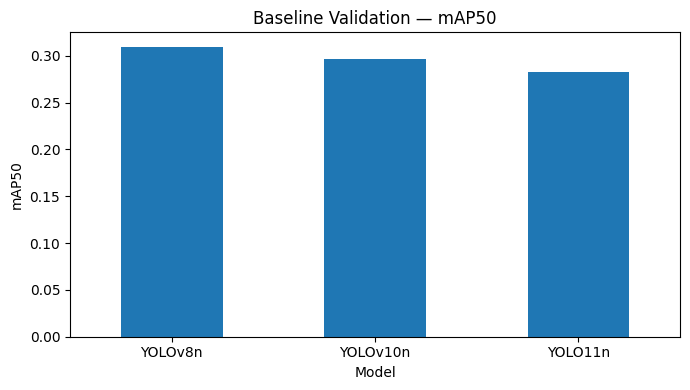

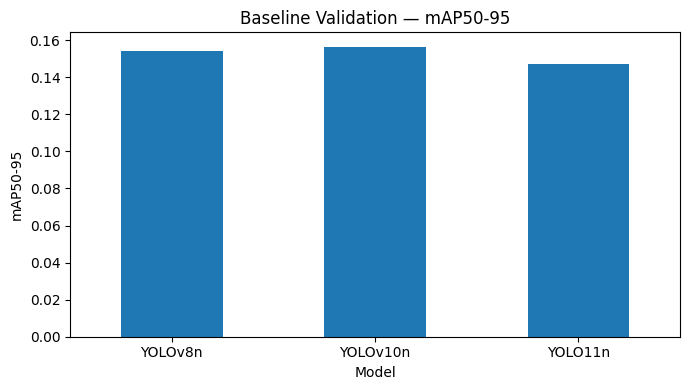

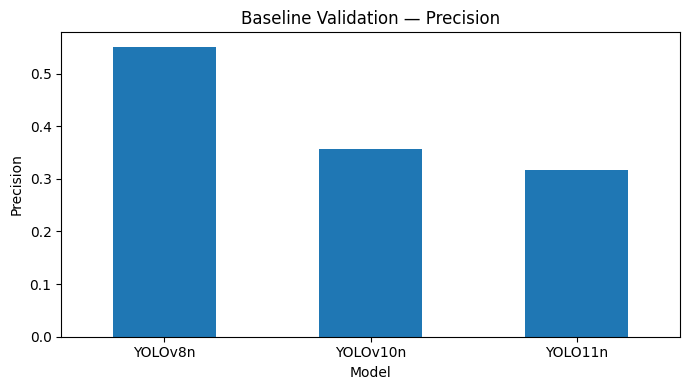

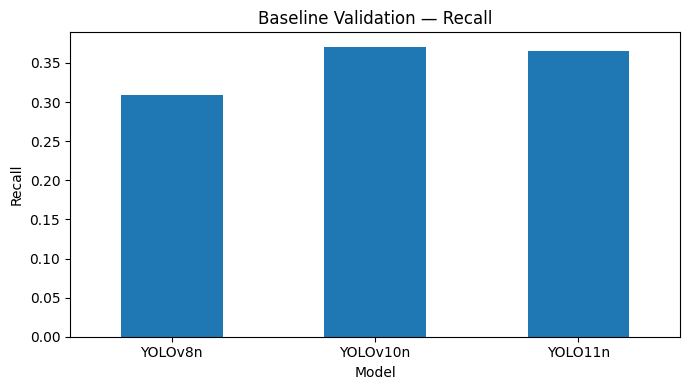

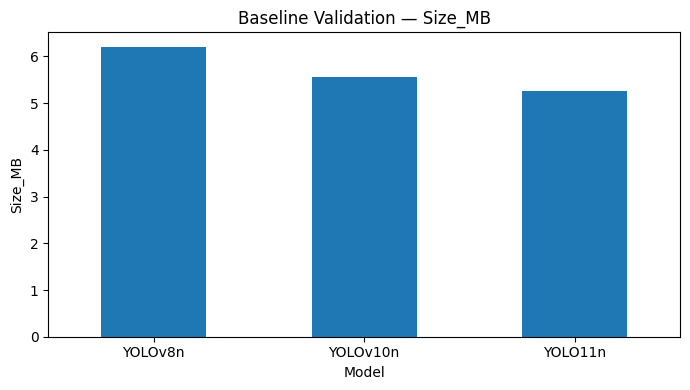

In [13]:
# Plot baseline comparison
metrics_to_plot = ["mAP50", "mAP50-95", "Precision", "Recall", "Size_MB"]

for metric in metrics_to_plot:
    ax = baseline_df.plot(
        x="Model",
        y=metric,
        kind="bar",
        legend=False,
        figsize=(7, 4)
    )
    ax.set_title(f"Baseline Validation — {metric}")
    ax.set_ylabel(metric)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [14]:
# Run hyperparameter tuning for each model
tuning_records = []

for model_label, base_weights in MODELS.items():
    for cfg in TUNE_CONFIGS:
        print("\n" + "=" * 80)
        print("TUNING:", model_label, "|", cfg["name"])
        print("=" * 80)

        model = YOLO(base_weights)
        run_name = f"tune_{model_label}_{cfg['name']}"

        train_result = model.train(
            data=DATA_YAML,
            epochs=TUNE_EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            optimizer=cfg["optimizer"],
            lr0=cfg["lr0"],
            weight_decay=cfg["weight_decay"],
            mosaic=cfg["mosaic"],
            patience=PATIENCE,
            seed=SEED,
            deterministic=True,
            device=DEVICE,
            workers=WORKERS,
            project=str(RUNS_DIR),
            name=run_name,
            exist_ok=True,
            plots=False,
            verbose=True,
        )

        best_path = Path(train_result.save_dir) / "weights" / "best.pt"
        tuned_model = YOLO(str(best_path))

        val_metrics = tuned_model.val(
            data=DATA_YAML,
            split="val",
            imgsz=IMGSZ,
            batch=BATCH,
            device=DEVICE,
            workers=WORKERS,
            plots=False,
            verbose=False,
        )

        rec = {
            "Model": model_label,
            "Trial": cfg["name"],
            "optimizer": cfg["optimizer"],
            "lr0": cfg["lr0"],
            "weight_decay": cfg["weight_decay"],
            "mosaic": cfg["mosaic"],
            "Best checkpoint": str(best_path),
            **extract_ultralytics_metrics(val_metrics),
            "Size_MB": checkpoint_size_mb(best_path),
            "Parameters": parameter_count(tuned_model),
        }

        tuning_records.append(rec)
        display(pd.DataFrame([rec]))

        del model, tuned_model
        cleanup()

tuning_df = pd.DataFrame(tuning_records)
tuning_df.to_csv(RESULTS_DIR / "tuning_validation_results.csv", index=False)
display(tuning_df.sort_values(["Model", "mAP50-95"], ascending=[True, False]))


TUNING: YOLOv8n | adamw_lr1e3
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tune_YOLOv8n_adam

,Model,Trial,optimizer,lr0,weight_decay,mosaic,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv8n,adamw_lr1e3,AdamW,0.001,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.327594,0.169311,0.380107,0.377262,6.204752,3139704



TUNING: YOLOv8n | adamw_lr5e4
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=tune_YOLOv8n_ada

,Model,Trial,optimizer,lr0,weight_decay,mosaic,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv8n,adamw_lr5e4,AdamW,0.0005,0.001,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.298196,0.154103,0.339092,0.352411,6.204752,3139704



TUNING: YOLOv8n | sgd_lr1e2
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tune_YOLOv8n_sgd_lr1

...


TUNING: YOLO11n | adamw_lr5e4
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=tune_YOLO11n_ada

,Model,Trial,optimizer,lr0,weight_decay,mosaic,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLO11n,adamw_lr5e4,AdamW,0.0005,0.001,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.308691,0.164665,0.414264,0.385473,5.251917,2606584



TUNING: YOLO11n | sgd_lr1e2
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_kaggle.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tune_YOLO11n_sgd_lr1

,Model,Trial,optimizer,lr0,weight_decay,mosaic,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLO11n,sgd_lr1e2,SGD,0.01,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.316687,0.15767,0.463822,0.381997,5.251917,2606584


,Model,Trial,optimizer,lr0,weight_decay,mosaic,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
7,YOLO11n,adamw_lr5e4,AdamW,0.0005,0.0010,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.308691,0.164665,0.414264,0.385473,5.251917,2606584
8,YOLO11n,sgd_lr1e2,SGD,0.0100,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.316687,0.157670,0.463822,0.381997,5.251917,2606584
6,YOLO11n,adamw_lr1e3,AdamW,0.0010,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.297246,0.150588,0.335810,0.361082,5.251917,2606584
4,YOLOv10n,adamw_lr5e4,AdamW,0.0005,0.0010,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.306671,0.158375,0.497925,0.375305,5.552546,2740528
5,YOLOv10n,sgd_lr1e2,SGD,0.0100,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.286780,0.143806,0.347509,0.360225,5.552546,2740528
3,YOLOv10n,adamw_lr1e3,AdamW,0.0010,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.285898,0.143072,0.364848,0.311735,5.552546,2740528
0,YOLOv8n,adamw_lr1e3,AdamW,0.0010,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.327594,0.169311,0.380107,0.377262,6.204752,3139704
1,YOLOv8n,adamw_lr5e4,AdamW,0.0005,0.0010,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.298196,0.154103,0.339092,0.352411,6.204752,3139704
2,YOLOv8n,sgd_lr1e2,SGD,0.0100,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.271720,0.134707,0.307598,0.318028,6.204752,3139704


In [15]:
# Select the best tuning result for each model
best_tuned_rows = (
    tuning_df
    .sort_values("mAP50-95", ascending=False)
    .groupby("Model", as_index=False)
    .first()
)

print("Best hyperparameter configuration for each YOLO version:")
display(best_tuned_rows)
best_tuned_rows.to_csv(RESULTS_DIR / "best_tuned_per_model.csv", index=False)

Best hyperparameter configuration for each YOLO version:


,Model,Trial,optimizer,lr0,weight_decay,mosaic,Best checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLO11n,adamw_lr5e4,AdamW,0.0005,0.0010,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.308691,0.164665,0.414264,0.385473,5.251917,2606584
1,YOLOv10n,adamw_lr5e4,AdamW,0.0005,0.0010,0.5,/kaggle/working/road_damage_project/runs/tune_...,0.306671,0.158375,0.497925,0.375305,5.552546,2740528
2,YOLOv8n,adamw_lr1e3,AdamW,0.0010,0.0005,1.0,/kaggle/working/road_damage_project/runs/tune_...,0.327594,0.169311,0.380107,0.377262,6.204752,3139704


In [16]:
# Evaluate the best tuned models on the test set
final_test_records = []

for _, row in best_tuned_rows.iterrows():
    model_label = row["Model"]
    ckpt = row["Best checkpoint"]

    print("\nTesting:", model_label)
    model = YOLO(ckpt)

    test_metrics = model.val(
        data=DATA_YAML,
        split="test",
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        workers=WORKERS,
        plots=True,
        verbose=False,
    )

    rec = {
        "Model": model_label,
        "Trial": row["Trial"],
        "Checkpoint": ckpt,
        **extract_ultralytics_metrics(test_metrics),
        "Size_MB": checkpoint_size_mb(ckpt),
        "Parameters": parameter_count(model),
    }

    final_test_records.append(rec)
    display(pd.DataFrame([rec]))

    del model
    cleanup()

final_test_df = pd.DataFrame(final_test_records)
final_test_df.to_csv(RESULTS_DIR / "final_test_detection_metrics.csv", index=False)
display(final_test_df)


Testing: YOLO11n
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1480.6±868.3 MB/s, size: 65.7 KB)
val: Scanning /kaggle/working/dataset/test/labels... 34 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 1.1Kit/s 0.0s
val: New cache created: /kaggle/working/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.9it/s 1.5s1.1s
                   all         34         72      0.561      0.638      0.642      0.417
Speed: 6.5ms preprocess, 7.2ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-13


,Model,Trial,Checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLO11n,adamw_lr5e4,/kaggle/working/road_damage_project/runs/tune_...,0.641629,0.417093,0.560847,0.63816,5.251917,2606584



Testing: YOLOv10n
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv10n summary (fused): 100 layers, 2,281,768 parameters, 0 gradients, 6.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1193.5±637.4 MB/s, size: 99.6 KB)
val: Scanning /kaggle/working/dataset/test/labels.cache... 34 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 7.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.2it/s 1.3s1.1s
                   all         34         72      0.669      0.466       0.65      0.397
Speed: 6.3ms preprocess, 6.2ms inference, 0.0ms loss, 3.3ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-14


,Model,Trial,Checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv10n,adamw_lr5e4,/kaggle/working/road_damage_project/runs/tune_...,0.649893,0.397386,0.669226,0.4662,5.552546,2740528



Testing: YOLOv8n
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,134,408 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1513.6±976.4 MB/s, size: 64.3 KB)
val: Scanning /kaggle/working/dataset/test/labels.cache... 34 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 10.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.9it/s 1.6s1.2s
                   all         34         72      0.539       0.66      0.671      0.416
Speed: 6.9ms preprocess, 10.3ms inference, 0.0ms loss, 5.2ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-15


,Model,Trial,Checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLOv8n,adamw_lr1e3,/kaggle/working/road_damage_project/runs/tune_...,0.671278,0.415836,0.539487,0.660058,6.204752,3139704


,Model,Trial,Checkpoint,mAP50,mAP50-95,Precision,Recall,Size_MB,Parameters
0,YOLO11n,adamw_lr5e4,/kaggle/working/road_damage_project/runs/tune_...,0.641629,0.417093,0.560847,0.638160,5.251917,2606584
1,YOLOv10n,adamw_lr5e4,/kaggle/working/road_damage_project/runs/tune_...,0.649893,0.397386,0.669226,0.466200,5.552546,2740528
2,YOLOv8n,adamw_lr1e3,/kaggle/working/road_damage_project/runs/tune_...,0.671278,0.415836,0.539487,0.660058,6.204752,3139704


In [17]:
# Functions to calculate IoU between boxes
def compute_iou_xyxy(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)
    inter = iw * ih

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

def read_gt_xyxy(img_path):
    image = Image.open(img_path)
    w, h = image.size

    label_path = Path(test_images).parent / "labels" / f"{Path(img_path).stem}.txt"
    gt = []

    if not label_path.exists():
        return gt

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue

            cls_id = int(float(parts[0]))
            xc, yc, bw, bh = map(float, parts[1:5])

            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h

            gt.append({
                "class_id": cls_id,
                "box": [x1, y1, x2, y2]
            })

    return gt

def match_image_predictions(pred_result, gt_objects, conf_threshold=0.25, iou_threshold=0.50):
    if pred_result.boxes is None or len(pred_result.boxes) == 0:
        return []

    xyxy = pred_result.boxes.xyxy.detach().cpu().numpy()
    conf = pred_result.boxes.conf.detach().cpu().numpy()
    cls = pred_result.boxes.cls.detach().cpu().numpy().astype(int)

    order = np.argsort(-conf)
    used_gt = set()
    matched_ious = []

    for idx in order:
        if conf[idx] < conf_threshold:
            continue

        pred_cls = int(cls[idx])
        pred_box = xyxy[idx].tolist()

        best_iou = 0.0
        best_gt_idx = None

        for gt_idx, gt in enumerate(gt_objects):
            if gt_idx in used_gt:
                continue
            if gt["class_id"] != pred_cls:
                continue

            iou = compute_iou_xyxy(pred_box, gt["box"])
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx

        if best_gt_idx is not None and best_iou >= iou_threshold:
            used_gt.add(best_gt_idx)
            matched_ious.append(best_iou)

    return matched_ious

In [18]:
# Calculate mean IoU on the test set
IOU_CONF = 0.25
IOU_MATCH_THRESHOLD = 0.50

test_image_list = image_files(test_images)
iou_records = []

for _, row in final_test_df.iterrows():
    model_label = row["Model"]
    model = YOLO(row["Checkpoint"])

    all_matched_ious = []

    for img_path in test_image_list:
        pred = model.predict(
            source=str(img_path),
            imgsz=IMGSZ,
            conf=IOU_CONF,
            device=DEVICE,
            verbose=False
        )[0]

        gt_objects = read_gt_xyxy(img_path)
        image_ious = match_image_predictions(
            pred,
            gt_objects,
            conf_threshold=IOU_CONF,
            iou_threshold=IOU_MATCH_THRESHOLD
        )
        all_matched_ious.extend(image_ious)

    rec = {
        "Model": model_label,
        "Mean_IoU": float(np.mean(all_matched_ious)) if all_matched_ious else np.nan,
        "Median_IoU": float(np.median(all_matched_ious)) if all_matched_ious else np.nan,
        "Matched_Detections": len(all_matched_ious),
    }

    iou_records.append(rec)
    display(pd.DataFrame([rec]))

    del model
    cleanup()

iou_df = pd.DataFrame(iou_records)
iou_df.to_csv(RESULTS_DIR / "test_iou_results.csv", index=False)
display(iou_df)

,Model,Mean_IoU,Median_IoU,Matched_Detections
0,YOLO11n,0.772798,0.805789,36


,Model,Mean_IoU,Median_IoU,Matched_Detections
0,YOLOv10n,0.80738,0.813031,31


,Model,Mean_IoU,Median_IoU,Matched_Detections
0,YOLOv8n,0.771148,0.78065,36


,Model,Mean_IoU,Median_IoU,Matched_Detections
0,YOLO11n,0.772798,0.805789,36
1,YOLOv10n,0.807380,0.813031,31
2,YOLOv8n,0.771148,0.780650,36


In [19]:
# Measure inference speed and FPS
BENCHMARK_IMAGES = min(100, len(test_image_list))
BENCHMARK_SAMPLE = [str(p) for p in test_image_list[:BENCHMARK_IMAGES]]

speed_records = []

for _, row in final_test_df.iterrows():
    model_label = row["Model"]
    model = YOLO(row["Checkpoint"])

    # Warm-up
    for img_path in BENCHMARK_SAMPLE[:min(5, len(BENCHMARK_SAMPLE))]:
        _ = model.predict(
            source=img_path,
            imgsz=IMGSZ,
            device=DEVICE,
            verbose=False
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    for img_path in BENCHMARK_SAMPLE:
        _ = model.predict(
            source=img_path,
            imgsz=IMGSZ,
            device=DEVICE,
            verbose=False
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    fps = len(BENCHMARK_SAMPLE) / elapsed if elapsed > 0 else np.nan
    latency_ms = (elapsed / len(BENCHMARK_SAMPLE)) * 1000 if BENCHMARK_SAMPLE else np.nan

    rec = {
        "Model": model_label,
        "Benchmark_images": len(BENCHMARK_SAMPLE),
        "Latency_ms_per_image": latency_ms,
        "FPS": fps,
    }
    speed_records.append(rec)
    display(pd.DataFrame([rec]))

    del model
    cleanup()

speed_df = pd.DataFrame(speed_records)
speed_df.to_csv(RESULTS_DIR / "test_speed_results.csv", index=False)
display(speed_df)

,Model,Benchmark_images,Latency_ms_per_image,FPS
0,YOLO11n,34,14.435445,69.273928


,Model,Benchmark_images,Latency_ms_per_image,FPS
0,YOLOv10n,34,13.859436,72.153008


,Model,Benchmark_images,Latency_ms_per_image,FPS
0,YOLOv8n,34,12.510327,79.933959


,Model,Benchmark_images,Latency_ms_per_image,FPS
0,YOLO11n,34,14.435445,69.273928
1,YOLOv10n,34,13.859436,72.153008
2,YOLOv8n,34,12.510327,79.933959


In [20]:
# Build the final model comparison table
comparison_df = (
    final_test_df
    .merge(iou_df, on="Model", how="left")
    .merge(speed_df, on="Model", how="left")
)

comparison_df = comparison_df[
    [
        "Model",
        "Trial",
        "mAP50",
        "mAP50-95",
        "Precision",
        "Recall",
        "Mean_IoU",
        "Median_IoU",
        "Matched_Detections",
        "Latency_ms_per_image",
        "FPS",
        "Size_MB",
        "Parameters",
        "Checkpoint",
    ]
]

comparison_df.to_csv(RESULTS_DIR / "FINAL_MODEL_COMPARISON.csv", index=False)
display(comparison_df)

,Model,Trial,mAP50,mAP50-95,Precision,Recall,Mean_IoU,Median_IoU,Matched_Detections,Latency_ms_per_image,FPS,Size_MB,Parameters,Checkpoint
0,YOLO11n,adamw_lr5e4,0.641629,0.417093,0.560847,0.638160,0.772798,0.805789,36,14.435445,69.273928,5.251917,2606584,/kaggle/working/road_damage_project/runs/tune_...
1,YOLOv10n,adamw_lr5e4,0.649893,0.397386,0.669226,0.466200,0.807380,0.813031,31,13.859436,72.153008,5.552546,2740528,/kaggle/working/road_damage_project/runs/tune_...
2,YOLOv8n,adamw_lr1e3,0.671278,0.415836,0.539487,0.660058,0.771148,0.780650,36,12.510327,79.933959,6.204752,3139704,/kaggle/working/road_damage_project/runs/tune_...


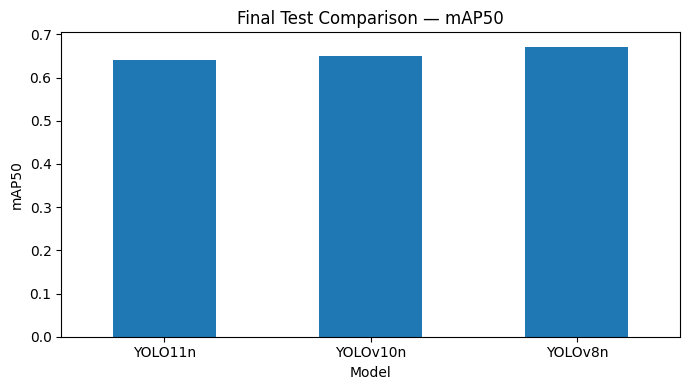

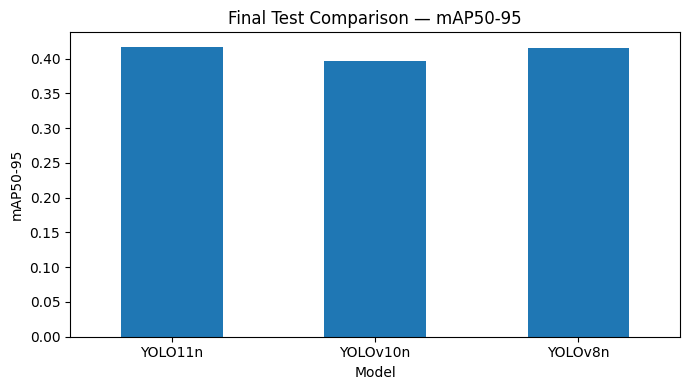

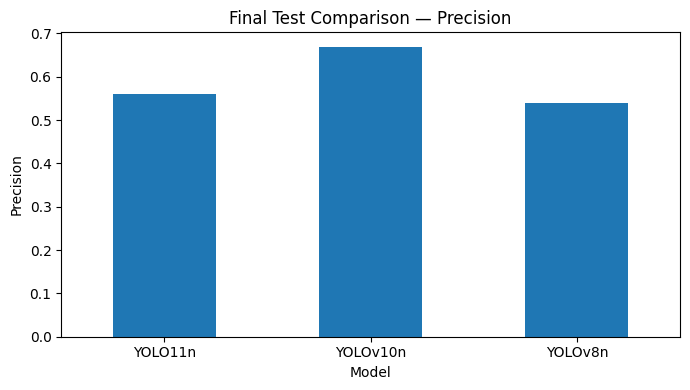

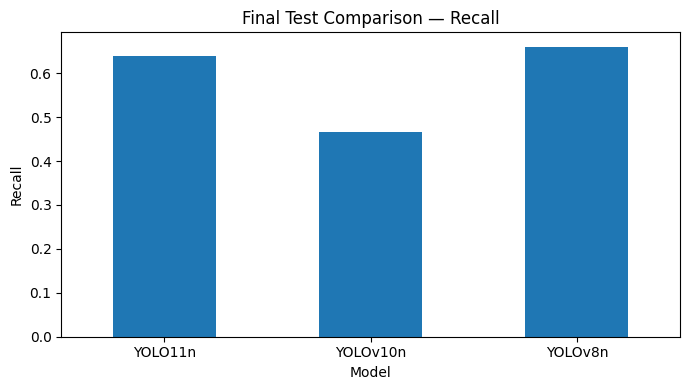

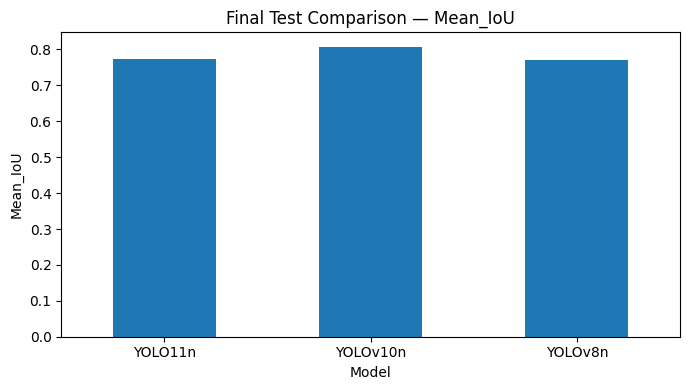

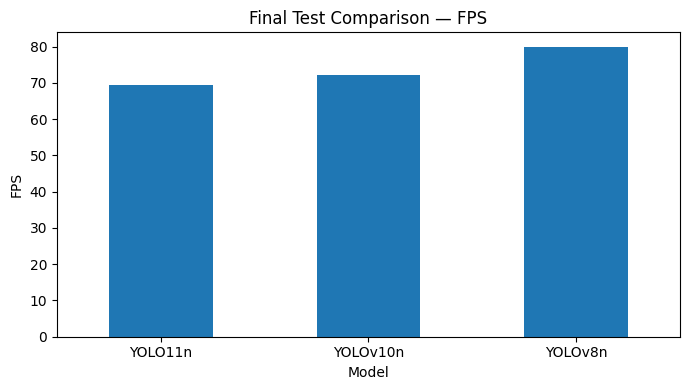

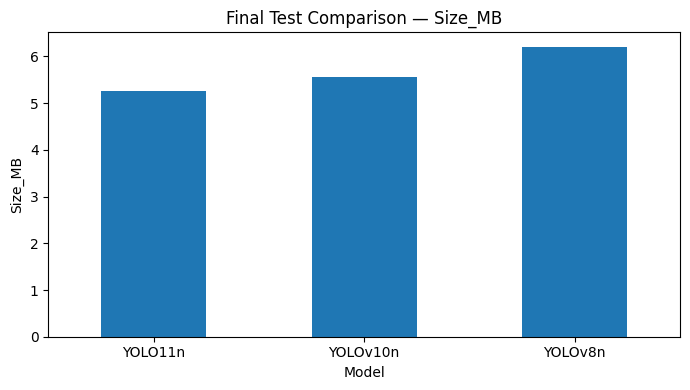

In [21]:
# Plot final comparison metrics
plot_metrics = [
    "mAP50",
    "mAP50-95",
    "Precision",
    "Recall",
    "Mean_IoU",
    "FPS",
    "Size_MB",
]

for metric in plot_metrics:
    ax = comparison_df.plot(
        x="Model",
        y=metric,
        kind="bar",
        legend=False,
        figsize=(7, 4)
    )
    ax.set_title(f"Final Test Comparison — {metric}")
    ax.set_ylabel(metric)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [22]:
# Calculate a simple deployment efficiency score
def minmax(series):
    s = pd.Series(series, dtype=float)
    if np.isclose(s.max(), s.min()):
        return pd.Series(np.ones(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())

eff_df = comparison_df.copy()

eff_df["Norm_mAP50-95"] = minmax(eff_df["mAP50-95"])
eff_df["Norm_FPS"] = minmax(eff_df["FPS"])

# Smaller model size = better, so invert normalized size.
size_norm = minmax(eff_df["Size_MB"])
eff_df["Norm_Compactness"] = 1 - size_norm

eff_df["Deployment_Efficiency_Score"] = (
    0.60 * eff_df["Norm_mAP50-95"]
    + 0.25 * eff_df["Norm_FPS"]
    + 0.15 * eff_df["Norm_Compactness"]
)

eff_df = eff_df.sort_values(
    "Deployment_Efficiency_Score",
    ascending=False
).reset_index(drop=True)

eff_df.to_csv(RESULTS_DIR / "deployment_efficiency_ranking.csv", index=False)

display(
    eff_df[
        [
            "Model",
            "mAP50-95",
            "FPS",
            "Size_MB",
            "Deployment_Efficiency_Score",
        ]
    ]
)

,Model,mAP50-95,FPS,Size_MB,Deployment_Efficiency_Score
0,YOLOv8n,0.415836,79.933959,6.204752,0.811718
1,YOLO11n,0.417093,69.273928,5.251917,0.750000
2,YOLOv10n,0.397386,72.153008,5.552546,0.170194


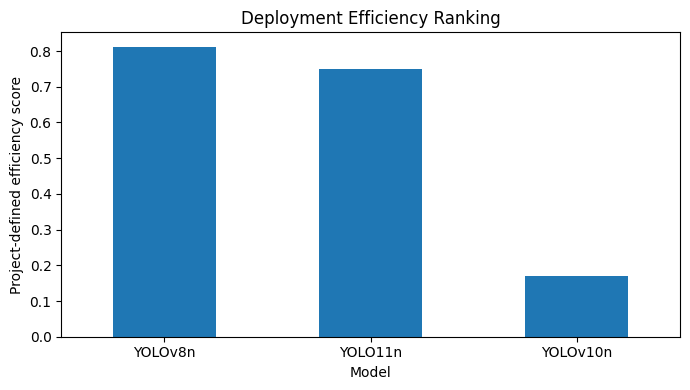

In [23]:
# Plot deployment efficiency ranking
ax = eff_df.plot(
    x="Model",
    y="Deployment_Efficiency_Score",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)
ax.set_title("Deployment Efficiency Ranking")
ax.set_ylabel("Project-defined efficiency score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
# Select the best model for deployment
best_row = eff_df.iloc[0]

BEST_MODEL_NAME = best_row["Model"]
BEST_MODEL_PATH = best_row["Checkpoint"]

print("Selected deployment model:", BEST_MODEL_NAME)
print("Checkpoint:", BEST_MODEL_PATH)
print("mAP50-95:", best_row["mAP50-95"])
print("FPS:", best_row["FPS"])
print("Size (MB):", best_row["Size_MB"])
print("Deployment efficiency score:", best_row["Deployment_Efficiency_Score"])

BEST_MODEL = YOLO(BEST_MODEL_PATH)

Selected deployment model: YOLOv8n
Checkpoint: /kaggle/working/road_damage_project/runs/tune_YOLOv8n_adamw_lr1e3/weights/best.pt
mAP50-95: 0.4158358869765871
FPS: 79.9339593150775
Size (MB): 6.204751968383789
Deployment efficiency score: 0.8117181493018574


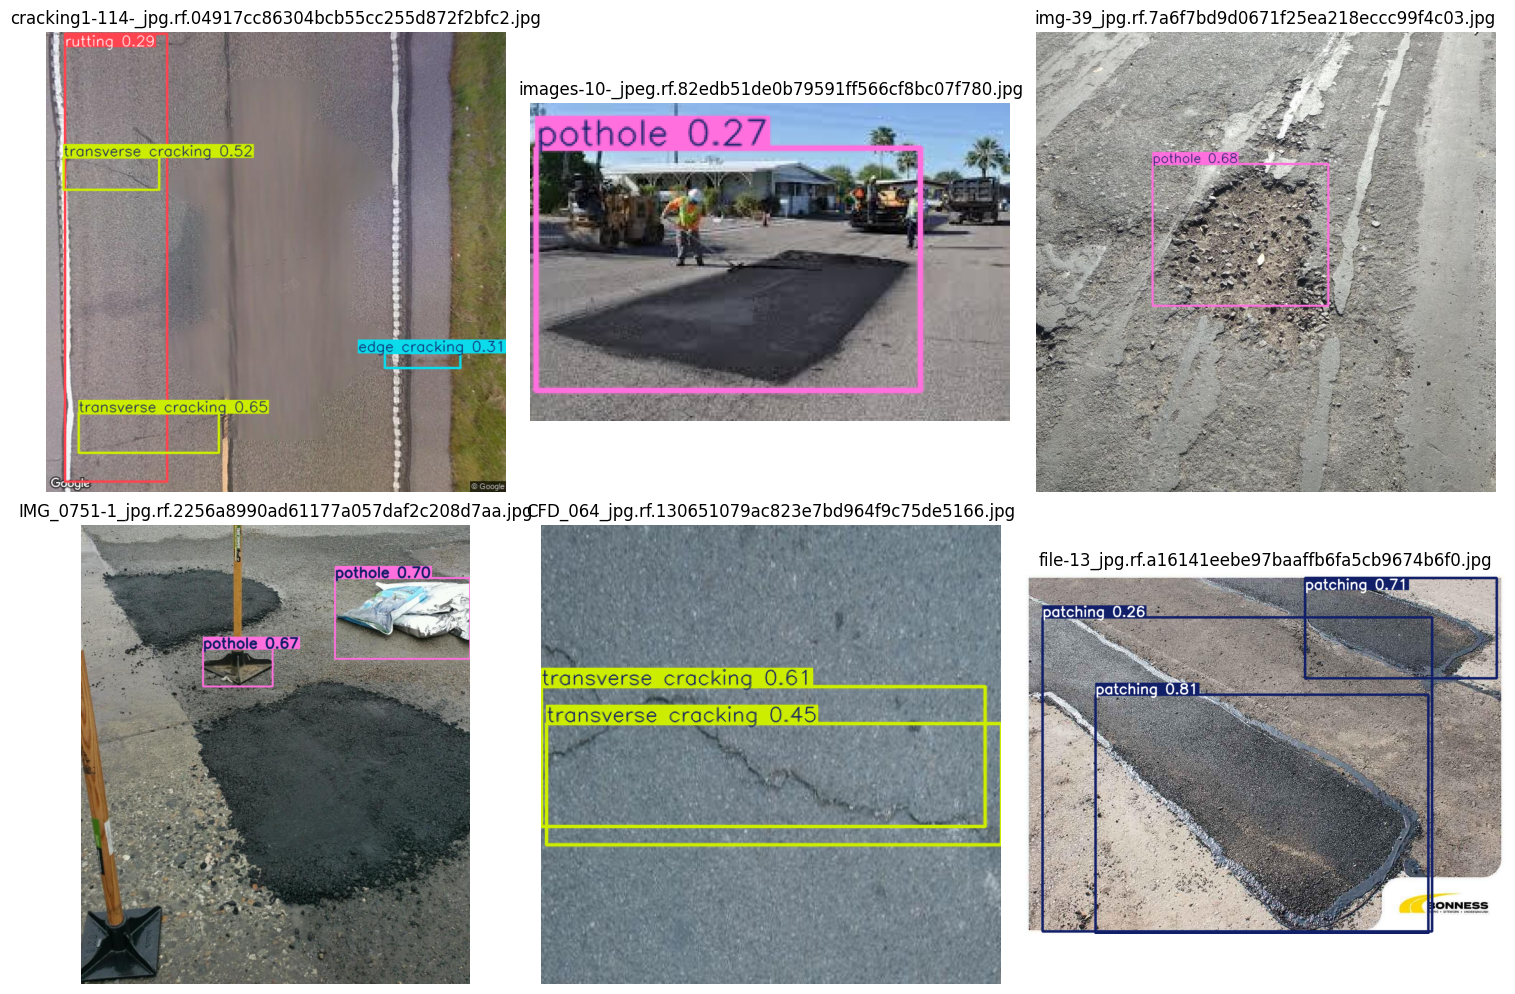

In [25]:
# Show predictions on test images
sample_test_images = random.sample(
    test_image_list,
    min(6, len(test_image_list))
)

fig, axes = plt.subplots(
    math.ceil(len(sample_test_images) / 3),
    3,
    figsize=(15, 10)
)
axes = np.array(axes).reshape(-1)

for ax in axes:
    ax.axis("off")

for ax, img_path in zip(axes, sample_test_images):
    result = BEST_MODEL.predict(
        source=str(img_path),
        imgsz=IMGSZ,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )[0]

    plotted_bgr = result.plot()
    plotted_rgb = plotted_bgr[..., ::-1]

    ax.imshow(plotted_rgb)
    ax.set_title(Path(img_path).name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
# Save and export the best model
BEST_PT = EXPORT_DIR / "best_road_damage_model.pt"
shutil.copy2(BEST_MODEL_PATH, BEST_PT)

print("Saved deployment checkpoint:", BEST_PT)

# Optional ONNX export
try:
    onnx_path = BEST_MODEL.export(
        format="onnx",
        imgsz=IMGSZ,
        dynamic=False,
        simplify=True
    )
    print("ONNX export:", onnx_path)
except Exception as e:
    print("ONNX export skipped/failed:", e)

Saved deployment checkpoint: /kaggle/working/road_damage_project/deployment/best_road_damage_model.pt
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,134,408 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/road_damage_project/runs/tune_YOLOv8n_adamw_lr1e3/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 12, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 369ms
Prepared 2 packages in 350ms
Installed 2 packages in 14ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to ta

In [27]:
# Print a short comparative analysis
report_df = comparison_df.copy()

best_map = report_df.loc[report_df["mAP50-95"].idxmax()]
best_precision = report_df.loc[report_df["Precision"].idxmax()]
best_recall = report_df.loc[report_df["Recall"].idxmax()]
best_iou = report_df.loc[report_df["Mean_IoU"].idxmax()]
best_fps = report_df.loc[report_df["FPS"].idxmax()]
smallest = report_df.loc[report_df["Size_MB"].idxmin()]

print("FINAL COMPARATIVE ANALYSIS")
print("-" * 80)
print(
    f"Highest test mAP@50:95: {best_map['Model']} "
    f"({best_map['mAP50-95']:.4f})"
)
print(
    f"Highest precision: {best_precision['Model']} "
    f"({best_precision['Precision']:.4f})"
)
print(
    f"Highest recall: {best_recall['Model']} "
    f"({best_recall['Recall']:.4f})"
)
print(
    f"Highest mean matched IoU: {best_iou['Model']} "
    f"({best_iou['Mean_IoU']:.4f})"
)
print(
    f"Fastest model: {best_fps['Model']} "
    f"({best_fps['FPS']:.2f} FPS)"
)
print(
    f"Smallest checkpoint: {smallest['Model']} "
    f"({smallest['Size_MB']:.2f} MB)"
)
print(
    f"Selected deployment model: {BEST_MODEL_NAME} "
    f"(efficiency score = {best_row['Deployment_Efficiency_Score']:.4f})"
)

FINAL COMPARATIVE ANALYSIS
--------------------------------------------------------------------------------
Highest test mAP@50:95: YOLO11n (0.4171)
Highest precision: YOLOv10n (0.6692)
Highest recall: YOLOv8n (0.6601)
Highest mean matched IoU: YOLOv10n (0.8074)
Fastest model: YOLOv8n (79.93 FPS)
Smallest checkpoint: YOLO11n (5.25 MB)
Selected deployment model: YOLOv8n (efficiency score = 0.8117)


**gradio interface**

In [28]:
# =========================
# GRADIO INTERFACE - ONE CELL
# =========================

!pip install -q gradio

from pathlib import Path
import torch
import gradio as gr
from ultralytics import YOLO

# 1) Find best model automatically
candidates = list(
    Path("/kaggle/working").glob("**/weights/best.pt")
)

if not candidates:
    candidates = list(
        Path("/kaggle/working").glob("**/best_road_damage_model.pt")
    )

if not candidates:
    raise FileNotFoundError(
        "No best.pt model found in /kaggle/working"
    )

# Use the most recently generated best model
BEST_MODEL = max(
    candidates,
    key=lambda p: p.stat().st_mtime
)

print("Using model:")
print(BEST_MODEL)

# 2) Load model
DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMGSZ = 640

model = YOLO(str(BEST_MODEL))

print("Model loaded successfully ✅")


# 3) Prediction function
def detect_road_damage(image, confidence):

    if image is None:
        return None, "Please upload a road image."

    result = model.predict(
        source=image,
        imgsz=IMGSZ,
        conf=float(confidence),
        device=DEVICE,
        verbose=False
    )[0]

    # Draw detections
    annotated = result.plot()

    # BGR -> RGB
    annotated = annotated[:, :, ::-1]

    # Detection details
    if result.boxes is None or len(result.boxes) == 0:

        details = (
            "No road damage detected above "
            "the selected confidence threshold."
        )

    else:

        classes = (
            result.boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )

        scores = (
            result.boxes.conf
            .cpu()
            .numpy()
        )

        lines = []

        for i, (cls_id, score) in enumerate(
            zip(classes, scores),
            start=1
        ):

            class_name = result.names[
                int(cls_id)
            ]

            lines.append(
                f"{i}. {class_name} "
                f"— Confidence: {score:.3f}"
            )

        details = (
            f"Total detections: {len(lines)}\n\n"
            + "\n".join(lines)
        )

    return annotated, details


# 4) Gradio App
demo = gr.Interface(

    fn=detect_road_damage,

    inputs=[
        gr.Image(
            type="numpy",
            label="Upload Road Image"
        ),

        gr.Slider(
            minimum=0.05,
            maximum=0.95,
            value=0.25,
            step=0.05,
            label="Confidence Threshold"
        )
    ],

    outputs=[
        gr.Image(
            label="Road Damage Detection"
        ),

        gr.Textbox(
            label="Detection Details",
            lines=10
        )
    ],

    title="🛣️ Road Damage Detection System",

    description=(
        "Upload a road image and the YOLO model "
        "will automatically detect and classify road damage."
    )
)


# 5) Launch
demo.launch(share=True)

Using model:
/kaggle/working/road_damage_project/runs/tune_YOLO11n_sgd_lr1e2/weights/best.pt
Model loaded successfully ✅
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://cc2fac835cb6bd9253.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
